# STEM scholarship corpus: architecture and execution guide

This notebook documents and runs the `stem_corpus.py` script from the preceding response. **Save that full script as `stem_corpus.py` beside this notebook before running.** This is a companion notebook, not a replacement implementation.

Audience: high-school juniors, seniors, gap-year applicants and explicitly eligible incoming freshmen. Outputs are source text and validated program-page records. Embeddings, vector storage, retrieval and evaluation are deferred. Stage 5 chunking is available as an optional final step.

**Execution status:** Documentation and code cells have been checked locally; no live API extraction or pilot has been run for this notebook. Counts and success rates must come from your run.

Run one stage at a time in VS Code. Paid cells are disabled until their local switch is deliberately changed. Do not use Run All to approve stages automatically.


## Architecture

The diagram follows the existing script. Budget reservations happen before each Tavily request; responses and reported usage are appended afterward. The pilot runs mapping, extraction and metadata on five supplied sites. Stage 1 discovery begins only after pilot review.


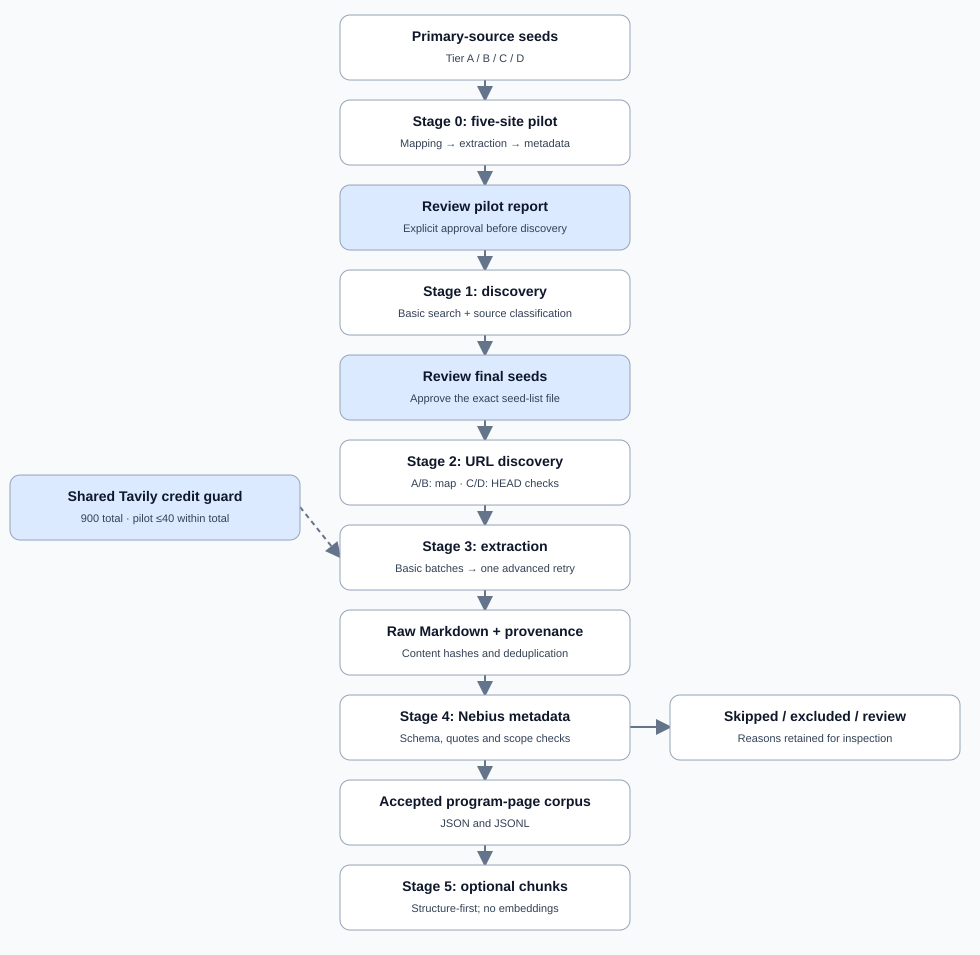

In [ ]:
# Architecture preview is already embedded below. No API calls.


## Source tiers

| Tier | Sources | Discovery approach |
|---|---|---|
| A | National foundations, corporate and merit programs for high-school applicants | Bounded map with program-related path filters |
| B | Community and professional organizations serving women, Hispanic, Black, Native American, Asian, first-gen, rural and disabled STEM students | Bounded map with the same filters |
| C | University STEM merit scholarships and honors programs | Seed URL plus constructed paths verified with HEAD |
| D | State programs, starting with Virginia, Maryland and DC | Seed URL plus constructed paths verified with HEAD |

These are **source categories**, not quality rankings. A college seed does not prove that a qualifying scholarship exists. Keep the pilot to five distinct registered domains covering all four tiers, plus a fifth site chosen for its JavaScript-heavy content. That designation requires your review; the script does not measure JavaScript usage.


## 1. Prepare the VS Code environment

Select a Python 3.11+ notebook kernel. Save the previous `stem_corpus.py` alongside the notebook. Install the listed packages in that kernel if needed. Keep keys in a local `.env`; never put keys into notebook cells or commit them.

The script loads `.env` when a subprocess starts. Its `.env.example` is written inside the output directory, but the actual `.env` should be placed beside `stem_corpus.py` for this workflow. API model names and the Nebius base URL are supplied by you.


In [1]:
# Run once if these packages are not installed in the selected kernel:
# %pip install requests python-dotenv pydantic tldextract pypdf

from pathlib import Path
import csv
import json
import subprocess
import sys
import os
import json
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_pinecone import PineconeVectorStore
from pinecone import Pinecone
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.prompts import ChatPromptTemplate, PromptTemplate

PROJECT = Path.cwd().resolve()
SCRIPT = PROJECT / "stem_corpus.py"
OUTPUT = PROJECT / "stem_corpus_output"
assert SCRIPT.exists(), f"Save the previous full script here first: {SCRIPT}"
print("Python:", sys.version.split()[0])
print("Project:", PROJECT)
print("Output:", OUTPUT)

def run_stage(stage, *flags):
    """Run the script with the notebook's interpreter. Flags contain no secrets."""
    command = [sys.executable, str(SCRIPT), stage, "--output", str(OUTPUT), *flags]
    subprocess.run(command, cwd=PROJECT, check=True)

def show_json(relative):
    path = OUTPUT / relative
    if not path.exists():
        print("Not created yet:", relative)
        return None
    value = json.loads(path.read_text(encoding="utf-8"))
    print(json.dumps(value, ensure_ascii=False, indent=2))
    return value


Python: 3.12.7
Project: C:\Users\Rosh\GENAI\WEEK2_PROJECT\college_resources_for_high_schoolers_STEM
Output: C:\Users\Rosh\GENAI\WEEK2_PROJECT\college_resources_for_high_schoolers_STEM\stem_corpus_output


In [2]:
#Loading enviornment variables from .env file
load_dotenv()
NEBIUS_BASE_URL="https://api.tokenfactory.nebius.com/v1"

In [4]:
# Free: create empty seed templates and configuration documentation.
%cd "C:/Users/Rosh/GENAI/WEEK2_PROJECT/college_resources_for_high_schoolers_STEM"
!python stem_corpus.py init

C:\Users\Rosh\GENAI\WEEK2_PROJECT\college_resources_for_high_schoolers_STEM
Populate seeds/seeds.csv and five-site seeds/pilot.csv.


## 2. Configure credentials and model availability

Create `.env` beside the script with these entries (replace the empty values locally):

```dotenv
TAVILY_API_KEY=
NEBIUS_API_KEY=
NEBIUS_BASE_URL=
NEBIUS_LLM_MODEL=
NEBIUS_EMBED_MODEL=
```

`NEBIUS_EMBED_MODEL` is reserved for the later embedding phase and is unused here. Preflight fetches Tavily pricing documentation and the authenticated Nebius model list. It does not make a Tavily data request or a generation request. The model-list response may omit prices; this script does not automatically choose the cheapest model.

Pricing verification is a heuristic text-pattern check and warns on uncertainty. It does not independently prove that provider billing has not changed.


In [ ]:
#In the next cell, run the preflight and pilot commands to ensure that the project is set up correctly and that the pilot has completed successfully. If the pilot has not completed, you will need to run it before proceeding.
!python stem_corpus.py preflight
!python stem_corpus.py pilot


Preflight is disabled. Configure .env, then enable this cell.


In [ ]:
#1. Run the five-site pilot if it hasn’t completed:
!python stem_corpus.py pilot --output stem_corpus_output

## 3. Prepare the five-site pilot

Fill `stem_corpus_output/seeds/pilot.csv` with **five real primary-source URLs**, columns `url,tier,org_name`. Use at least one A, B, C and D source; use the fifth for your JS-heavy test. Verify that each source is public and permits the intended access. Do not paste aggregators or application login portals.

Populate `seeds/seeds.csv` separately for the later discovery stage. The pilot file does not automatically populate the main seed file. In particular, curated university seeds are needed because the current discovery query list has no Tier C university queries.

The script deduplicates by registered domain. Multiple campuses or subdomains on one registered domain can collapse to one seed. This is a coverage tradeoff to inspect.


In [ ]:
#Creating the pilot final_seeds.csv file with the five distinct domains covering tiers A, B, C and D for test purposes
!python stem_corpus.py discover --approve-pilot --output stem_corpus_output

In [ ]:
# Free: inspect the pilot seed file before any paid requests.
!python stem_corpus.py map --approve-seeds --output stem_corpus_output
print("Rows:", len(pilot_seeds))
print("Expected: five distinct primary-source domains covering A, B, C and D.")


[]
Rows: 0
Expected: five distinct primary-source domains covering A, B, C and D.


## Budget reservations and logging

| Allocation | Maximum Tavily credits |
|---|---:|
| Discovery | 150 |
| Mapping | 300 |
| Extraction | 350 |
| Explicit extraction retries | 100 |
| Overall | **900** |
| Pilot, included in the allocations above | **40** |

Before each request, `ledger.jsonl` receives endpoint, parameters, stage, tier/domain, estimated cost and reserved maximum. Page counts and reported usage are null until the response arrives. A completion event records returned counts and usage afterward.

Reservations use the requested upper bound and remain charged conservatively even if actual usage is lower. Failed or uncertain identical requests are blocked from automatic repayment. Basic-to-advanced extraction retry is a distinct request charged to `retries`. HTTP/transport retries are not automatic.

An extract batch of 20 URLs reserves 4 credits at basic depth or 8 at advanced depth. A map limited to 30 pages without instructions reserves 3. The pilot consumes these same stage allocations; it does not add 40 to 900. Reuse the same output folder so reservations and response caches survive restarts. This ledger cannot limit spending by other applications.


## Stage 0 — run and review the pilot

The pilot verifies/collects a small set of URLs, extracts text, validates metadata and produces `reports/pilot_report.json`. Up to four candidate URLs are retained per pilot site. It does not run the main seed-discovery stage.

The script stops after writing the pilot report. Inspect failures and scope decisions before approving expansion. Validation success measures JSON/schema and quote checks, not full semantic accuracy. Duplicate pages excluded from storage affect the reported storage yield.


In [ ]:
#Extract page content
!python stem_corpus.py extract --output "C:\Users\Rosh\GENAI\WEEK2_PROJECT\college_resources_for_high_schoolers_STEM\stem_corpus_output"



Pilot disabled; no paid request made by this cell.


In [8]:
pilot_report = show_json("reports/pilot_report.json")


Not created yet: reports/pilot_report.json


## Stage 1 — discover and review primary-source seeds

After you review the pilot, enable the next cell. Basic Tavily searches return candidate snippets; Nebius classifies source type using title/snippet. Known aggregators and social sites are excluded. Your curated seed rows are combined with retained results and deduplicated by registered domain.

**Limit:** the fixed query list does not guarantee the original ~250-site target. There are no automatic quotas or exhaustive searches. Classification from snippets is preliminary; review the final list yourself.

The command writes `seeds/seeds_final.csv` and stops. The next stage requires approval tied to the exact file hash. Editing the file later invalidates that approval.


In [ ]:
!python stem_corpus.py discover --approve-pilot --output stem_corpus_output


Stopped at the pilot-review gate.


In [ ]:
# Free: review a sample and counts; open the full CSV in VS Code too.
!python stem_corpus.py map --approve-seeds --output stem_corpus_output
print("Run discovery after pilot review to create the final seed list.")


Run discovery after pilot review to create the final seed list.


## Stage 2 — targeted URL discovery

A/B sources use Tavily map with limit 30, depth 2, program-related include paths and excluded news/login/career paths. C/D sources are not mapped: the script tries the supplied seed plus common scholarship/honors paths and verifies live URLs with direct HTTP requests.

The implementation retains at most eight A/B candidate URLs or four C/D URLs per source during the main run. Default paths will miss institutions with different URL structures; inspect `urls/candidates.csv` and skipped reasons. HEAD checks and robots reads do not consume Tavily credits. Robots failures are treated conservatively.


In [ ]:
#Extract page content
!python stem_corpus.py extract --output "C:\Users\Rosh\GENAI\WEEK2_PROJECT\college_resources_for_high_schoolers_STEM\stem_corpus_output"

Review seeds_final.csv before enabling mapping.


## Stage 3 — extract, retain provenance and deduplicate

Basic extraction uses batches of up to 20 URLs, grouped by domain/tier for budget attribution. Missing/failed results receive one advanced attempt under the retry allocation. Raw Markdown and sidecar JSON are saved by URL hash. Sidecars contain provenance, fetch time, extraction depth and normalized-content hash.

Exact duplicate content is skipped. Near-duplicates use five-word shingle Jaccard similarity >=0.9. This is suitable for a small corpus but pairwise comparisons become slower as the corpus grows. Likely PDFs ending in `.pdf` are checked for page count; PDFs over 20 pages are skipped. Extensionless PDF URLs are not detected by this check.

The `http_status` sidecar field remains null when Tavily does not expose the origin status. A successful Tavily HTTP response is not proof that every requested page was extracted.


In [12]:
RUN_PAID_EXTRACTION = False
if RUN_PAID_EXTRACTION:
    run_stage("extract")
else:
    print("Extraction disabled.")


Extraction disabled.


## Stage 4 — normalize and validate with Nebius

Heuristics remove selected boilerplate before a structured Nebius call. Pydantic checks types and constraints. Evidence quotes must occur in source text and contain at most 25 words per field. The script requires affirmative evidence for target-applicant eligibility and STEM relevance; ambiguous pages go to review.

Only accepted program pages enter `data/program_pages.json` and `.jsonl`. Other states distinguish non-program pages, unsuitable applicant stages, unrelated programs and cases needing review. Invalid responses/provider errors are logged separately. A schema/JSON error can trigger one repair request; evidence validation errors outside that call are logged for review rather than automatically retried.

**Interpretation limits:** quote presence does not prove that the quote supports every normalized claim. Manually inspect dates, dollar amounts and eligibility. Records represent pages, not consolidated programs. Do not count several pages for one scholarship as several opportunities. Previous-cycle deadlines are retained as stated; no current-open status is inferred.


In [ ]:
#Extract metadata
!python stem_corpus.py metadata --output "C:\Users\Rosh\GENAI\WEEK2_PROJECT\college_resources_for_high_schoolers_STEM\stem_corpus_output"

Nebius metadata extraction disabled.


In [5]:
# Free: inspect status counts, null rates and budget after a stage.
show_json("reports/corpus_stats.json")
show_json("reports/credit_report.json")


{
  "raw_pages": 160,
  "raw_pages_by_tier": {
    "A": 65,
    "B": 92,
    "D": 3
  },
  "metadata_statuses": {
    "excluded_not_a_program": 74,
    "review_required": 12,
    "excluded_applicant_stage": 1,
    "accepted": 5,
    "excluded_not_stem_relevant": 2
  },
  "accepted_program_pages": 5,
  "with_parsed_deadline": 0,
  "with_award_amount": 3,
  "null_or_empty_rate_by_field": {
    "program_name": 0.0,
    "organization": 0.0,
    "page_type": 0.0,
    "award_type": 0.0,
    "award_amount_min_usd": 0.6,
    "award_amount_max_usd": 0.6,
    "award_amount_text": 0.4,
    "renewable": 0.8,
    "deadline_text": 0.8,
    "deadline_date_iso": 1.0,
    "deadline_recurs_annually": 1.0,
    "eligibility_summary": 0.0,
    "applicant_stage": 0.0,
    "stem_fields": 0.2,
    "gpa_minimum": 0.4,
    "citizenship_requirements": 1.0,
    "residency_restriction": 0.4,
    "demographic_focus": 0.2,
    "need_based": 0.4,
    "merit_based": 0.6,
    "essay_required": 0.8,
    "recommendation_

{'total_cap': 900,
 'pilot_cap_included_in_total': 40,
 'reserved_or_reported_credits': 190.0,
 'remaining': 710.0,
 'pilot_credits': 12.0,
 'pilot_remaining': 28.0,
 'by_stage': {'discovery': 15,
  'mapping': 111,
  'extraction': 54,
  'retries': 10},
 'by_tier': {'A': 71, 'B': 110, 'D': 9},
 'by_domain': {'coca-colascholarsfoundation.org': 4,
  'swe.org': 4,
  'jkcf.org': 4,
  '': 15,
  'nshss.org': 5,
  'uncf.org': 5,
  'edison.com': 5,
  'spacefoundation.org': 5,
  'scienceambassadorscholarship.org': 4,
  'nsf.gov': 7,
  'smartscholarship.org': 6,
  'aamu.edu': 5,
  'sfsu.edu': 7,
  'edu.ph': 3,
  'scholarshipamerica.org': 5,
  'aisd.net': 3,
  'uky.edu': 5,
  'pittstate.edu': 4,
  'stmarytx.edu': 3,
  'nhaainc.org': 4,
  'shpe.org': 4,
  'svcf.org': 5,
  'hsf.net': 4,
  'nsbe.org': 4,
  'naacp.org': 5,
  'accessandequity.org': 5,
  'st-aug.edu': 7,
  'asianpacificfund.org': 4,
  'apiascholars.org': 5,
  'norcocollege.edu': 5,
  'jonesanddemille.com': 4,
  'lariatfoundation.org': 4

In [6]:
# use Nebius to turn the raw pages into structured scholarship records:
!python stem_corpus.py metadata --output "C:\Users\Rosh\GENAI\WEEK2_PROJECT\college_resources_for_high_schoolers_STEM\stem_corpus_output"

## Outputs and handoff

| Path under the output folder | Purpose |
|---|---|
| `ledger.jsonl` | Durable pre-request reservations and post-response events |
| `data/responses/` | Cached Tavily responses |
| `data/raw/` | Markdown and provenance sidecars |
| `data/metadata/` | Validated per-page decisions and scope statuses |
| `data/program_pages.jsonl` | Accepted program-page corpus for the next phase |
| `review/metadata_review.json` | Ambiguous pages needing human decisions |
| `skipped.csv` | Access, duplicate, PDF and extraction reasons; created when needed |
| `failed_extractions.csv` | Metadata/provider failures; created when needed |
| `reports/pilot_report.json` | Five-site pilot metrics and stop status |
| `credit_report.md`, `corpus_stats.md` | Human-readable reports |
| `data/chunks.jsonl` | Optional Stage 5 output |

### Resume safely

Use the same output path. Successfully cached identical Tavily requests are reused. Raw pages and same-hash metadata are skipped. Failed/uncertain paid requests keep their reservations and need manual inspection; there is no automatic ledger reset. Deleting cache/ledger files can lose spend protection. The current script has no freshness refresh command, cross-page program consolidation, embedding/index implementation or gold-set evaluation.

### Next phase

Review accepted records and unresolved eligibility before chunking/indexing. Later work can add program consolidation, current-cycle status, refresh logic, model-tokenizer chunk sizing, Nebius embeddings, local vector storage, BM25 and measured hybrid retrieval.

### Reference documentation

- [Tavily credit rules](https://docs.tavily.com/documentation/api-credits)
- [Tavily map](https://docs.tavily.com/documentation/api-reference/endpoint/map)
- [Tavily extract](https://docs.tavily.com/documentation/api-reference/endpoint/extract)
- [Nebius structured output](https://docs.tokenfactory.nebius.com/ai-models-inference/json)

The preflight check is intended to surface changes at execution time; no live model availability or pricing is certified by this notebook.
